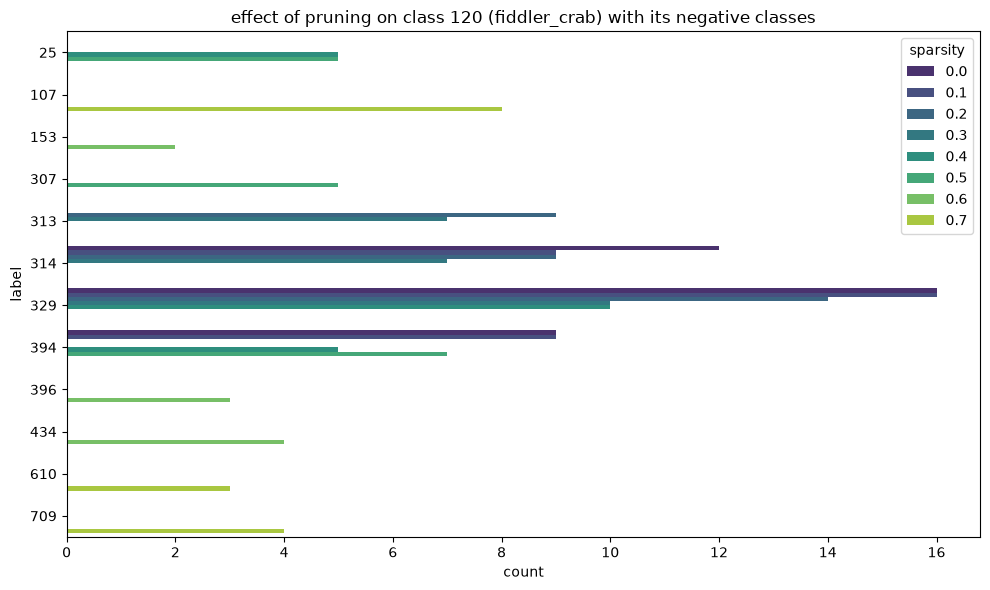

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import json

with open('../imagenet-labels.json') as f:
   labels = json.load(f)

prunings = [
'global-unstructured-L1',
   # 'local-unstructured-L1',
]
levels = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
target_class = 120

# ------------------------------------------------------------------
# 1. Collect data
# ------------------------------------------------------------------
data = []
for p in prunings:
   for l in levels:
      df = pd.read_csv(f'../results/negative-similarity/vit_b_16/all-minmax-{p}-{l}.csv')
      temp = (
        df[(df['target_class_idx'] == target_class) & (df['order'] <= 3)]
        .sort_values('order')[['order', 'least_class_idx', 'least_class_count']]
        .reset_index(drop=True)
      )
      for _, row in temp.iterrows():
        label_i = int(row["least_class_idx"])
        data.append({
           "sparsity": float(l),
           "label":   ,
           "count":   int(row["least_class_count"]),
        })

# ------------------------------------------------------------------
# 2. Build & clean DataFrame
# ------------------------------------------------------------------
df = pd.DataFrame(data)

df["sparsity"] = df["sparsity"].astype(float).round(2).astype(str)  # categorical hue
df["label"]   = df["label"].astype(int).astype(str)
df["count"]   = pd.to_numeric(df["count"], errors="coerce")
df = df.dropna(subset=["sparsity", "label", "count"])

# Collapse duplicate (label, sparsity) rows so each bar is unique
df = df.groupby(["sparsity", "label"], as_index=False)["count"].sum()

# ------------------------------------------------------------------
# 3. Consistent ordering
# ------------------------------------------------------------------
order    = sorted(df["label"].unique(),   key=int)    # numeric label order
hue_order = sorted(df["sparsity"].unique(), key=float)  # numeric sparsity order

# ------------------------------------------------------------------
# 4. Plot
# ------------------------------------------------------------------
plt.figure(figsize=(10, max(4, 0.5 * len(order))))
ax = sns.barplot(
   data=df,
   y="label",
   x="count",
   hue="sparsity",
   order=order,
   hue_order=hue_order,
   orient="h",
   estimator="sum",
   errorbar=None,
   palette="viridis",
)
ax.set(title=f"effect of pruning on class {target_class} ({labels[str(target_class)]}) with its negative classes")

# ------------------------------------------------------------------
# 5. Legend sanity check + styling
# ------------------------------------------------------------------
handles, labels = ax.get_legend_handles_labels()
plt.tight_layout()

In [15]:
df = pd.read_csv(f'../results/negative-similarity/vit_b_16/confident-minmax-global-unstructured-L1-0.1.csv')
df[(df['least_class_count'] > 20)]

,Unnamed: 0,target_class_idx,order,most_class_idx,most_class_count,least_class_idx,least_class_count
0,128,16,1,16,49,131,31
1,248,31,1,31,48,41,30
2,471,59,1,59,44,0,26
3,472,59,2,55,20,329,21
4,575,72,1,72,49,310,22
...,...,...,...,...,...,...,...
56,7091,888,1,888,49,918,43
57,7307,915,1,915,50,483,32
58,7331,918,1,918,48,888,39
59,7332,918,2,611,3,938,27
